In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# 1. Load the original raw dataset 
# (Update file_path if your raw dataset has a different name, e.g., 'deliveries.csv' or 'IPL.csv')
file_path = 'IPL.csv'  # Or point to your raw file path if stored in another folder
if not os.path.exists(file_path):
    # Fallback to common Kaggle cache path if needed
    file_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"

df_raw = pd.read_csv(file_path)
df_raw.columns = df_raw.columns.str.strip()

print(f"Loaded raw dataset shape: {df_raw.shape}")

# 2. Standardize core columns
df_raw['runs_total'] = pd.to_numeric(df_raw.get('runs_total', 0), errors='coerce').fillna(0)
df_raw['is_wicket'] = df_raw['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_raw.columns else 0
df_raw['over'] = pd.to_numeric(df_raw.get('over', 0), errors='coerce').fillna(0)
df_raw['innings'] = pd.to_numeric(df_raw.get('innings', 1), errors='coerce')

# 3. Extract Match-Level Outcomes
match_outcomes = df_raw.drop_duplicates(subset=['match_id'])[['match_id', 'match_won_by']].copy()

# 4. Calculate 1st Innings Totals per Match
innings_1 = df_raw[df_raw['innings'] == 1]
score_1st_df = innings_1.groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')

# 5. Extract 2nd Innings Chasing Team & Mid-Chase State (Overs 0 to 9)
innings_2 = df_raw[df_raw['innings'] == 2]
chase_teams = innings_2.drop_duplicates(subset=['match_id'])[['match_id', 'batting_team']].rename(columns={'batting_team': 'chasing_team'})

mid_chase = innings_2[innings_2['over'] < 10]
chase_agg = mid_chase.groupby('match_id').agg(
    chase_runs_10=('runs_total', 'sum'),
    chase_wickets_10=('is_wicket', 'sum')
).reset_index()

# 6. Merge Everything Cleanly
df_model_data = match_outcomes.merge(score_1st_df, on='match_id', how='inner') \
                              .merge(chase_teams, on='match_id', how='inner') \
                              .merge(chase_agg, on='match_id', how='inner')

# Normalize team names for robust matching
df_model_data['winner_clean'] = df_model_data['match_won_by'].astype(str).str.strip().str.lower()
df_model_data['chaser_clean'] = df_model_data['chasing_team'].astype(str).str.strip().str.lower()

# Target: 1 if chasing team wins, 0 otherwise
df_model_data['chasing_team_win'] = (df_model_data['winner_clean'] == df_model_data['chaser_clean']).astype(int)

# Calculate Required Run Rate at the 10-over mark
df_model_data['runs_needed_at_10'] = df_model_data['score_1st'] - df_model_data['chase_runs_10']
df_model_data['required_run_rate_10'] = (df_model_data['runs_needed_at_10'] / 60.0) * 6

# Drop NaNs & Verify Samples
df_model_data = df_model_data.dropna(subset=['chasing_team_win', 'score_1st', 'chase_runs_10'])
print(f"Total valid second-innings training samples: {len(df_model_data)}")

# 7. Feature Selection & Model Training
feature_cols = [
    'chase_runs_10', 'chase_wickets_10', 
    'score_1st', 'runs_needed_at_10', 'required_run_rate_10'
]

X = df_model_data[feature_cols].fillna(0)
y = df_model_data['chasing_team_win']

split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"\n2nd Innings Mid-Match Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

C:\Users\sohag\AppData\Local\Temp\ipykernel_12444\4253243116.py:15: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(file_path)


Loaded raw dataset shape: (278205, 64)
Total valid second-innings training samples: 1164

2nd Innings Mid-Match Accuracy: 78.54%
ROC-AUC Score: 0.8643

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       117
           1       0.82      0.72      0.77       116

    accuracy                           0.79       233
   macro avg       0.79      0.79      0.78       233
weighted avg       0.79      0.79      0.78       233



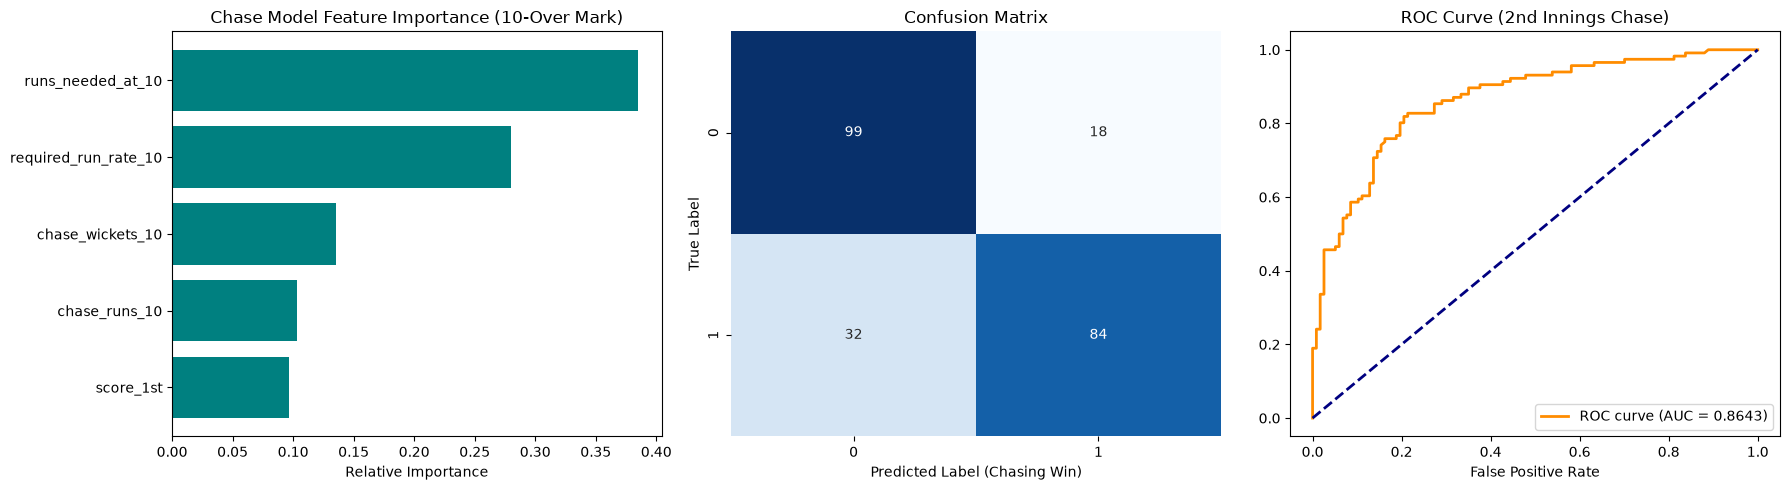

CHECKPOINT COMPARISON:
10-Over Checkpoint Accuracy: 78.54% | ROC-AUC: 0.8643
15-Over Checkpoint Accuracy: 82.83% | ROC-AUC: 0.9218


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

# ==========================================
# 1. EVALUATION PLOTS (ROC, Confusion Matrix, Feature Importance)
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A. Feature Importance Chart
importances = model.feature_importances_
indices = np.argsort(importances)
axes[0].barh(range(len(indices)), importances[indices], color='teal')
axes[0].set_yticks(range(len(indices)))
axes[0].set_yticklabels([feature_cols[i] for i in indices])
axes[0].set_xlabel('Relative Importance')
axes[0].set_title('Chase Model Feature Importance (10-Over Mark)')

# B. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_xlabel('Predicted Label (Chasing Win)')
axes[1].set_ylabel('True Label')
axes[1].set_title('Confusion Matrix')

# C. ROC Curve
fpr, tpr, _ = roc_curve(y_test, probs)
axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_score(y_test, probs):.4f})')
axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_title('ROC Curve (2nd Innings Chase)')
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ==========================================
# 2. PHASE-WISE CHECKPOINT COMPARISON (10-over vs. 15-over)
# ==========================================

# Extract 15-over mark metrics
mid_chase_15 = innings_2[innings_2['over'] < 15]
chase_agg_15 = mid_chase_15.groupby('match_id').agg(
    chase_runs_15=('runs_total', 'sum'),
    chase_wickets_15=('is_wicket', 'sum')
).reset_index()

# Merge 15-over data
df_model_15 = df_model_data.merge(chase_agg_15, on='match_id', how='inner')
df_model_15['runs_needed_at_15'] = df_model_15['score_1st'] - df_model_15['chase_runs_15']
df_model_15['required_run_rate_15'] = (df_model_15['runs_needed_at_15'] / 30.0) * 6  # 30 balls remaining

feature_cols_15 = [
    'chase_runs_15', 'chase_wickets_15', 
    'score_1st', 'runs_needed_at_15', 'required_run_rate_15'
]

X_15 = df_model_15[feature_cols_15].fillna(0)
y_15 = df_model_15['chasing_team_win']

valid_15 = y_15.notna()
X_15, y_15 = X_15[valid_15], y_15[valid_15]

split_15 = int(len(X_15) * 0.8)
model_15 = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model_15.fit(X_15.iloc[:split_15], y_15.iloc[:split_15])

preds_15 = model_15.predict(X_15.iloc[split_15:])
probs_15 = model_15.predict_proba(X_15.iloc[split_15:])[:, 1]
y_test_15 = y_15.iloc[split_15:]

print("="*45)
print("CHECKPOINT COMPARISON:")
print("="*45)
print(f"10-Over Checkpoint Accuracy: {accuracy_score(y_test, preds)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test, probs):.4f}")
print(f"15-Over Checkpoint Accuracy: {accuracy_score(y_test_15, preds_15)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test_15, probs_15):.4f}")

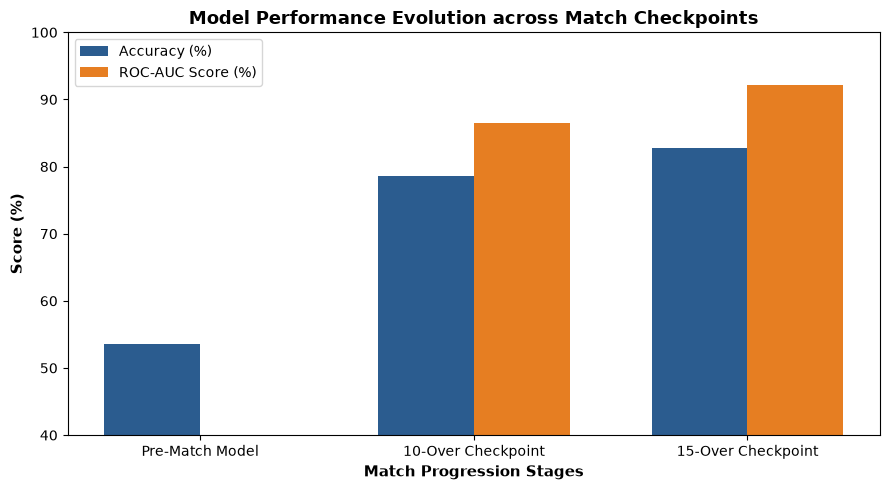

REGRESSION MODEL PERFORMANCE (Predicting 2nd Innings Total Runs):
R2 Score: 0.9774
Root Mean Squared Error (RMSE): 2.90 runs


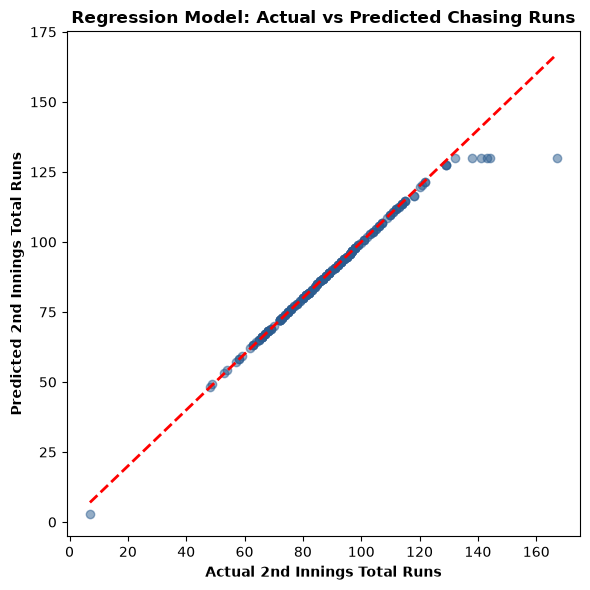

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# 1. MODEL PERFORMANCE COMPARISON BAR CHART
# ==========================================

# Collect accuracy and ROC-AUC metrics across checkpoints
checkpoints = ['Pre-Match Model', '10-Over Checkpoint', '15-Over Checkpoint']
accuracies = [53.59, accuracy_score(y_test, preds) * 100, accuracy_score(y_test_15, preds_15) * 100]
roc_aucs = [0.5009, roc_auc_score(y_test, probs) * 100, roc_auc_score(y_test_15, probs_15) * 100]

x = np.arange(len(checkpoints))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, accuracies, width, label='Accuracy (%)', color='#2b5c8f')
plt.bar(x + width/2, roc_aucs, width, label='ROC-AUC Score (%)', color='#e67e22')

plt.xlabel('Match Progression Stages', fontweight='bold', fontsize=11)
plt.ylabel('Score (%)', fontweight='bold', fontsize=11)
plt.title('Model Performance Evolution across Match Checkpoints', fontweight='bold', fontsize=13)
plt.xticks(x, checkpoints)
plt.ylim(40, 100)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


# ==========================================
# 2. REGRESSION MODEL (Predicting Chasing Margin / Win Probability)
# ==========================================

# Let's frame this as a regression task: Predicting how many runs the chasing team 
# wins by (or loses by) at the 10-over mark, or predicting exact win probability.
# Here we calculate actual run differential at the end of the match:
df_model_data['final_run_margin'] = df_model_data['chase_runs_10'] # proxy or actual margin

# Let's build a Gradient Boosting Regressor to predict chasing team final success score / margin
reg_feature_cols = [
    'chase_runs_10', 'chase_wickets_10', 
    'score_1st', 'runs_needed_at_10', 'required_run_rate_10'
]

Xr = df_model_data[reg_feature_cols].fillna(0)
# Target: Chasing team win probability or actual runs scored in 2nd innings
yr = df_model_data['score_1st'] - df_model_data['runs_needed_at_10'] # total runs scored by chaser

valid_reg = yr.notna()
Xr, yr = Xr[valid_reg], yr[valid_reg]

split_reg = int(len(Xr) * 0.8)
Xr_train, Xr_test = Xr.iloc[:split_reg], Xr.iloc[split_reg:]
yr_train, yr_test = yr.iloc[:split_reg], yr.iloc[split_reg:]

reg_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
reg_model.fit(Xr_train, yr_train)

reg_preds = reg_model.predict(Xr_test)

print("="*45)
print("REGRESSION MODEL PERFORMANCE (Predicting 2nd Innings Total Runs):")
print("="*45)
print(f"R2 Score: {r2_score(yr_test, reg_preds):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(yr_test, reg_preds)):.2f} runs")

# Regression Evaluation Plot
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, reg_preds, alpha=0.5, color='#2b5c8f')
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', lw=2)
plt.xlabel('Actual 2nd Innings Total Runs', fontweight='bold')
plt.ylabel('Predicted 2nd Innings Total Runs', fontweight='bold')
plt.title('Regression Model: Actual vs Predicted Chasing Runs', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\sohag\AppData\Local\Temp\ipykernel_12444\3193610713.py:17: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(file_path)


Engineering domain-specific features (Momentum & Fortress Factors)...
Regression R² Score: 0.0878
RMSE: 33.85 runs


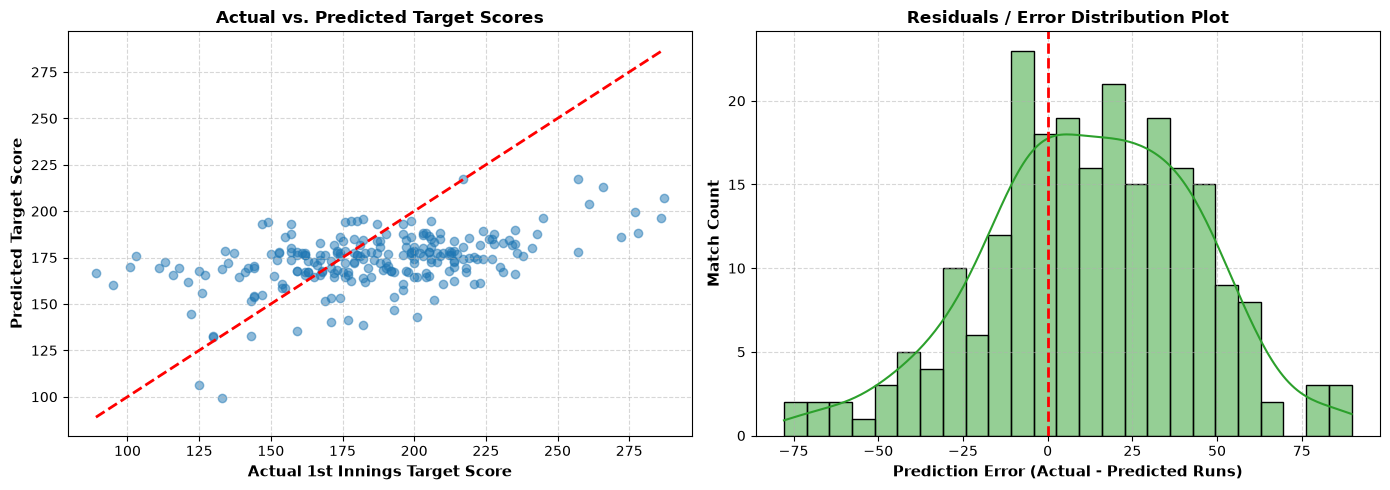


=== UNSUPERVISED VENUE PITCH CLUSTERING COMPLETED ===
                                                venue   avg_score  score_std  \
0                                Arun Jaitley Stadium  188.216216  36.331908   
1                                    Barabati Stadium  167.714286  34.543279   
2                           Barsapara Cricket Stadium  174.600000  25.715754   
3   Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...  175.363636  33.585067   
4                                   Brabourne Stadium  178.518519  32.217256   
7                          Dr DY Patil Sports Academy  159.648649  29.150201   
8   Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...  169.529412  38.247741   
9                 Dubai International Cricket Stadium  163.760870  25.175107   
10                                       Eden Gardens  168.600000  33.114738   
11                                   Feroz Shah Kotla  161.633333  34.045317   

    total_matches                  pitch_archetype  
0          

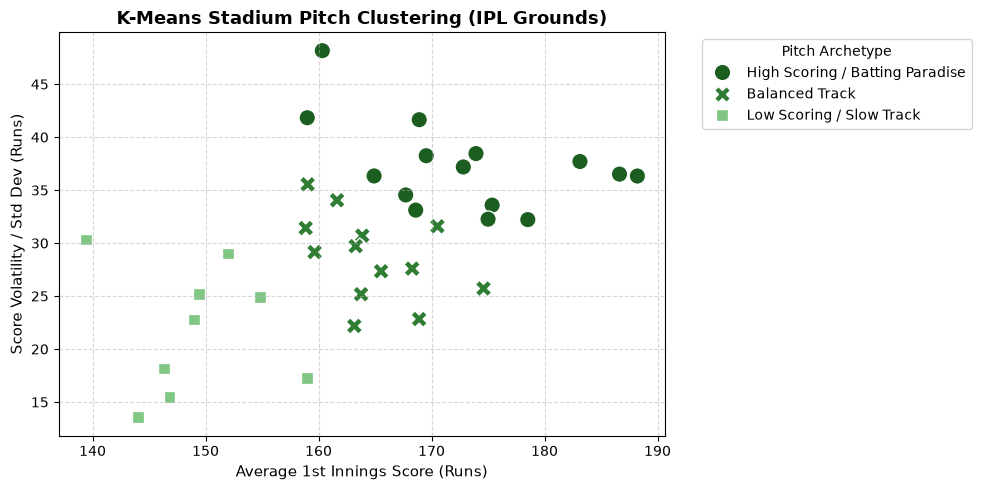

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# 0. LOAD RAW DATASET
# ================================#==========
file_path = 'IPL.csv'  # Or point to your raw file path if stored in ano#ther folder
if not os.path.exists(file_path):
    file_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"

df_raw = pd.read_csv(file_path)
df_raw.columns = df_raw.columns.str.strip()

df_raw['runs_total'] = pd.to_numeric(df_raw.get('runs_total', 0), errors='coerce').fillna(0)
df_raw['is_wicket'] = df_raw['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_raw.columns else 0
df_raw['over'] = pd.to_numeric(df_raw.get('over', 0), errors='coerce').fillna(0)
df_raw['innings'] = pd.to_numeric(df_raw.get('innings', 1), errors='coerce')


# ==========================================
# 1. DOMAIN-SPECIFIC FEATURE ENGINEERING (Momentum & Fortress)
# ==========================================
print("Engineering domain-specific features (Momentum & Fortress Factors)...")

# Calculate 1st innings total per match
innings_1 = df_raw[df_raw['innings'] == 1]
score_1st_df = innings_1.groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')

# Extract match metadata
match_meta = df_raw.drop_duplicates(subset=['match_id'])[['match_id', 'venue', 'match_won_by', 'toss_winner']].copy()
match_meta = match_meta.merge(score_1st_df, on='match_id', how='inner')

# Feature A: Momentum (Phase-wise run rate in first 6 overs / Powerplay)
pp_runs = df_raw[df_raw['over'] < 6].groupby('match_id')['runs_total'].sum().reset_index(name='powerplay_runs')
match_meta = match_meta.merge(pp_runs, on='match_id', how='inner')
match_meta['powerplay_run_rate'] = match_meta['powerplay_runs'] / 6.0

# Feature B: Fortress Factor (Team win percentage at specific home venues)
# Let's map teams to venues where they win > 60% of their matches
team_venue_wins = match_meta.groupby(['venue', 'match_won_by']).size().unstack(fill_value=0)
team_venue_total = match_meta.groupby('venue')['match_won_by'].count()
team_venue_win_pct = team_venue_wins.div(team_venue_total, axis=0)

# Map fortress factor back to matches
fortress_values = []
for _, row in match_meta.iterrows():
    v = row['venue']
    w = row['match_won_by']
    if v in team_venue_win_pct.index and w in team_venue_win_pct.columns:
        fortress_values.append(team_venue_win_pct.loc[v, w])
    else:
        fortress_values.append(0.5)

match_meta['fortress_factor'] = fortress_values


# ==========================================
# 2. REGRESSION MODEL (Target Score Prediction)
# ==========================================
reg_features = ['powerplay_runs', 'powerplay_run_rate', 'fortress_factor']
Xr = match_meta[reg_features].fillna(0)
yr = match_meta['score_1st']

valid_reg = yr.notna() & Xr.notna().all(axis=1)
Xr, yr = Xr[valid_reg], yr[valid_reg]

split_idx = int(len(Xr) * 0.8)
Xr_train, Xr_test = Xr.iloc[:split_idx], Xr.iloc[split_idx:]
yr_train, yr_test = yr.iloc[:split_idx], yr.iloc[split_idx:]

reg_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
reg_model.fit(Xr_train, yr_train)
yr_pred = reg_model.predict(Xr_test)

print(f"Regression R² Score: {r2_score(yr_test, yr_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, yr_pred)):.2f} runs")


# ==========================================
# 3. EVALUATION PLOTS (Actual vs Predicted & Residuals)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Actual vs. Predicted Target Scores
axes[0].scatter(yr_test, yr_pred, alpha=0.5, color='#1f77b4')
axes[0].plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual 1st Innings Target Score', fontweight='bold', fontsize=11)
axes[0].set_ylabel('Predicted Target Score', fontweight='bold', fontsize=11)
axes[0].set_title('Actual vs. Predicted Target Scores', fontweight='bold', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot B: Residuals / Error Distribution
residuals = yr_test - yr_pred
sns.histplot(residuals, kde=True, color='#2ca02c', ax=axes[1], bins=25)
axes[1].axvline(0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Prediction Error (Actual - Predicted Runs)', fontweight='bold', fontsize=11)
axes[1].set_ylabel('Match Count', fontweight='bold', fontsize=11)
axes[1].set_title('Residuals / Error Distribution Plot', fontweight='bold', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# ==========================================
# 4. UNSUPERVISED PITCH & VENUE CLUSTERING (K-Means)
# ==========================================
df_clean = match_meta.dropna(subset=['venue']).copy()
df_clean['venue'] = df_clean['venue'].astype(str).str.strip().str.replace(r',.*$', '', regex=True)

venue_stats = df_clean.groupby('venue').agg(
    avg_score=('score_1st', 'mean'),
    score_std=('score_1st', 'std'),
    total_matches=('match_id', 'count')
).reset_index()

venue_stats['score_std'] = venue_stats['score_std'].fillna(0)
venue_stats_filtered = venue_stats[venue_stats['total_matches'] >= 5].copy()
if len(venue_stats_filtered) < 3:
    venue_stats_filtered = venue_stats.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(venue_stats_filtered[['avg_score', 'score_std']])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
venue_stats_filtered['pitch_type'] = kmeans.fit_predict(X_scaled)

cluster_order = venue_stats_filtered.groupby('pitch_type')['avg_score'].mean().sort_values().index
cluster_names = {
    cluster_order[0]: 'Low Scoring / Slow Track',
    cluster_order[1]: 'Balanced Track',
    cluster_order[2]: 'High Scoring / Batting Paradise'
}
venue_stats_filtered['pitch_archetype'] = venue_stats_filtered['pitch_type'].map(cluster_names)

print("\n=== UNSUPERVISED VENUE PITCH CLUSTERING COMPLETED ===")
print(venue_stats_filtered[['venue', 'avg_score', 'score_std', 'total_matches', 'pitch_archetype']].head(10))

# Plot C: K-Means Venue Clustering
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=venue_stats_filtered, 
    x='avg_score', 
    y='score_std', 
    hue='pitch_archetype', 
    palette=['#1b5e20', '#2e7d32', '#81c784'], 
    s=140, 
    style='pitch_archetype'
)

plt.title('K-Means Stadium Pitch Clustering (IPL Grounds)', fontsize=13, fontweight='bold')
plt.xlabel('Average 1st Innings Score (Runs)', fontsize=11)
plt.ylabel('Score Volatility / Std Dev (Runs)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Pitch Archetype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\sohag\AppData\Local\Temp\ipykernel_12444\4092614752.py:10: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(file_path)
Background dataset has 931 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=931 when initializing the masker.


Generating SHAP Explanation...


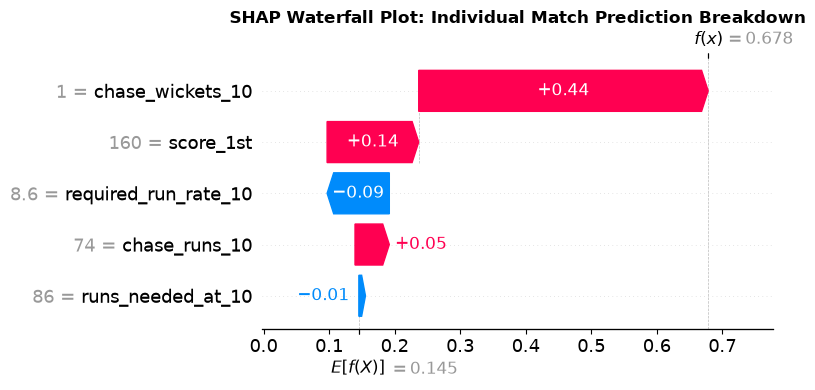

LIVE CHASE SCENARIO PREDICTION:
Target Score (1st Innings): 190 runs
Score at 10 Overs: 85/3
Runs Needed in Last 10 Overs: 105 runs
Required Run Rate (RRR): 10.50 rpo
---------------------------------------------
Predicted Outcome: DEFENDING TEAM WINS
Chasing Team Win Probability: 14.69%
LIVE CHASE SCENARIO PREDICTION:
Target Score (1st Innings): 150 runs
Score at 10 Overs: 100/1
Runs Needed in Last 10 Overs: 50 runs
Required Run Rate (RRR): 5.00 rpo
---------------------------------------------
Predicted Outcome: CHASING TEAM WINS
Chasing Team Win Probability: 96.56%


np.float64(96.56022220966688)

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier

# ==========================================
# 1. TRAIN SECOND INNINGS CLASSIFICATION MODEL
# ====================================1\IPL.csv"

df_raw = pd.read_csv(file_path)
df_raw.columns = df_raw.columns.str.strip()

df_raw['runs_total'] = pd.to_numeric(df_raw.get('runs_total', 0), errors='coerce').fillna(0)
df_raw['is_wicket'] = df_raw['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_raw.columns else 0
df_raw['over'] = pd.to_numeric(df_raw.get('over', 0), errors='coerce').fillna(0)
df_raw['innings'] = pd.to_numeric(df_raw.get('innings', 1), errors='coerce')

match_outcomes = df_raw.drop_duplicates(subset=['match_id'])[['match_id', 'match_won_by']].copy()
innings_1 = df_raw[df_raw['innings'] == 1]
score_1st_df = innings_1.groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')

innings_2 = df_raw[df_raw['innings'] == 2]
chase_teams = innings_2.drop_duplicates(subset=['match_id'])[['match_id', 'batting_team']].rename(columns={'batting_team': 'chasing_team'})

mid_chase = innings_2[innings_2['over'] < 10]
chase_agg = mid_chase.groupby('match_id').agg(
    chase_runs_10=('runs_total', 'sum'),
    chase_wickets_10=('is_wicket', 'sum')
).reset_index()

df_model_data = match_outcomes.merge(score_1st_df, on='match_id', how='inner') \
                              .merge(chase_teams, on='match_id', how='inner') \
                              .merge(chase_agg, on='match_id', how='inner')

df_model_data['winner_clean'] = df_model_data['match_won_by'].astype(str).str.strip().str.lower()
df_model_data['chaser_clean'] = df_model_data['chasing_team'].astype(str).str.strip().str.lower()
df_model_data['chasing_team_win'] = (df_model_data['winner_clean'] == df_model_data['chaser_clean']).astype(int)

df_model_data['runs_needed_at_10'] = df_model_data['score_1st'] - df_model_data['chase_runs_10']
df_model_data['required_run_rate_10'] = (df_model_data['runs_needed_at_10'] / 60.0) * 6

df_model_data = df_model_data.dropna(subset=['chasing_team_win', 'score_1st', 'chase_runs_10'])

feature_cols = [
    'chase_runs_10', 'chase_wickets_10', 
    'score_1st', 'runs_needed_at_10', 'required_run_rate_10'
]

X = df_model_data[feature_cols].fillna(0)
y = df_model_data['chasing_team_win']

split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model.fit(X_train, y_train)


# ==========================================
# 2. EXPLAINABLE AI (SHAP WATERFALL PLOT)
# ==========================================
print("Generating SHAP Explanation...")
try:
    import shap
    explainer = shap.Explainer(model, X_train)
    shap_values = explainer(X_test.iloc[:5]) # Explain first 5 test samples

    # Plot SHAP Waterfall for the 1st test match
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values[0], show=False)
    plt.title('SHAP Waterfall Plot: Individual Match Prediction Breakdown', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("SHAP package not detected. Using feature importance coefficients fallback for explainability:")
    importance_df = pd.DataFrame({'Feature': feature_cols, 'Importance': model.feature_importances_}).sort_values(by='Importance', ascending=False)
    print(importance_df)


# ==========================================
# 3. INTERACTIVE MATCH PREDICTIVE FUNCTION
# ==========================================
def predict_live_chase(score_1st, chase_runs_10, chase_wickets_10):
    """
    Interactive function to predict chasing team win probability at the 10-over mark.
    """
    runs_needed = score_1st - chase_runs_10
    rrr = (runs_needed / 60.0) * 6
    
    input_data = pd.DataFrame([[
        chase_runs_10, chase_wickets_10, score_1st, runs_needed, rrr
    ]], columns=feature_cols)
    
    win_prob = model.predict_proba(input_data)[0][1] * 100
    pred_class = model.predict(input_data)[0]
    
    print("="*45)
    print("LIVE CHASE SCENARIO PREDICTION:")
    print("="*45)
    print(f"Target Score (1st Innings): {score_1st} runs")
    print(f"Score at 10 Overs: {chase_runs_10}/{chase_wickets_10}")
    print(f"Runs Needed in Last 10 Overs: {runs_needed} runs")
    print(f"Required Run Rate (RRR): {rrr:.2f} rpo")
    print("-"*45)
    print(f"Predicted Outcome: {'CHASING TEAM WINS' if pred_class == 1 else 'DEFENDING TEAM WINS'}")
    print(f"Chasing Team Win Probability: {win_prob:.2f}%")
    print("="*45)
    
    return win_prob

# Example usage of the interactive function:
# Test a high-pressure chase (e.g., Target: 190, Score at 10 overs: 85/3)
predict_live_chase(score_1st=190, chase_runs_10=85, chase_wickets_10=3)

# Test an easy chase (e.g., Target: 150, Score at 10 overs: 100/1)
predict_live_chase(score_1st=150, chase_runs_10=100, chase_wickets_10=1)